# Spike 02: Same attack, Open Images plates

**Throwaway feasibility test.** Identical attack code to Spike 01; only the dataset and detector change,
so the two spikes can be compared directly.

**Question:** Does plate-restricted PGD still beat YOLOv8 on Open Images plates
(mostly UK/EU, about 15-20% US, smaller plates, much more varied scenes than Spike 01's parking garages)?

**Setup**
- Data: 200 random images from the Open Images V7 test split that contain a "Vehicle registration plate"
  at least `MIN_PLATE_PX` wide and `MIN_PLATE_H_PX` tall at the 640 input (CC BY). Smaller plates are not readable anyway.
- Model: Spike 01's YOLOv8**n** (trained on keremberke's Vietnamese garage photos), used **without retraining**.
  So this is also a baseline for how a plate detector transfers to a new kind of photo; expect lower clean recall.
  (Fine-tuning on Open Images comes later, in the real experiment.)
- Attacks (40 PGD steps each, noise only inside the plate box + 10% margin), same as Spike 01:
  - `rgb_8`: every RGB channel may move by up to 8/255
  - `ycbcr_y2_c8`: brightness Y up to 2/255, color Cb/Cr up to 8/255
    (the original version from Spike 01, including its known Y-budget leak, kept identical for comparison)
  - `random_rgb_8`: random +/-8/255 noise, no optimization

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from skimage.metrics import structural_similarity
from torchvision.ops import box_iou
from ultralytics import YOLO

ROOT = Path.cwd()
while not (ROOT / ".git").exists():  # notebook may be launched from its own folder
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data/openimages_plates"
WEIGHTS = ROOT / "weights/yasir_yolov8n/best.pt"
FIG_DIR = ROOT / "spikes/02_openimages/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_IMAGES = 200
IMGSZ = 640          # long side, matches how the detector was trained
CONF = 0.25          # detection confidence threshold
IOU_MATCH = 0.5      # a GT plate counts as "found" if a detection overlaps it with IoU >= 0.5
STEPS = 40
MARGIN = 0.10        # grow the plate box by 10% on each side for the noise region
TOPK = 100           # loss pushes down the 100 most confident plate candidates
MIN_PLATE_PX = 40    # keep images with a plate at least this wide at the 640 input...
MIN_PLATE_H_PX = 10  # ...and at least this tall

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.__version__)

cuda 2.11.0+cu128


## 1. Load images and ground-truth boxes

Labels are YOLO format: one `.txt` per image, one line per plate: `class cx cy w h`, normalized to [0, 1].
We convert to pixel `[x1, y1, x2, y2]` boxes and keep only images with a readable-size plate.

In [2]:
def load_yolo_boxes(img_path):
    W, H = Image.open(img_path).size
    rows = np.loadtxt(DATA_DIR / "labels/test" / f"{img_path.stem}.txt", ndmin=2)
    cx, cy, w, h = rows[:, 1] * W, rows[:, 2] * H, rows[:, 3] * W, rows[:, 4] * H
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=1)
    order = np.argsort(-w * h)                      # largest plate first, so boxes[0] is the main plate
    scale = IMGSZ / max(W, H)
    readable = (w[order[0]] * scale >= MIN_PLATE_PX) and (h[order[0]] * scale >= MIN_PLATE_H_PX)
    return torch.tensor(boxes[order], dtype=torch.float32), readable

all_images = sorted((DATA_DIR / "images/test").glob("*.jpg"))
candidates = []
for p in all_images:
    boxes, readable = load_yolo_boxes(p)
    if readable:
        candidates.append((p, boxes))

samples = random.Random(SEED).sample(candidates, N_IMAGES)
print(f"{len(all_images)} test images, {len(candidates)} with a plate >= {MIN_PLATE_PX}x{MIN_PLATE_H_PX}px, using {len(samples)}")

2062 test images, 1729 with a plate >= 40x10px, using 200


## 2. Preprocess into the model's input space

We attack the exact tensor the model sees: resize so the long side is 640 (keeping aspect ratio),
then pad to a multiple of 32 with gray (YOLO's network needs sizes divisible by its stride, 32).
Attacking in this space means there is no resizing between our noise and the model,
so the experiment measures the attack, not resampling artifacts.

In [3]:
def letterbox(path, boxes):
    img = Image.open(path).convert("RGB")
    scale = IMGSZ / max(img.size)
    w, h = round(img.width * scale), round(img.height * scale)
    img = img.resize((w, h), Image.BILINEAR)
    pad_w, pad_h = (-w) % 32, (-h) % 32
    x = torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float() / 255.0
    x = F.pad(x, (0, pad_w, 0, pad_h), value=114 / 255)
    return x.unsqueeze(0).to(device), (boxes * scale).to(device)

x0, b0 = letterbox(*samples[0])
print(x0.shape, b0)

/tmp/ipykernel_36818/3019719196.py:7: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(np.asarray(img)).permute(2, 0, 1).float() / 255.0


torch.Size([1, 3, 480, 640]) tensor([[164.1290, 300.3874, 233.2906, 324.1291]], device='cuda:0')


### Look at some samples

Worth checking by eye: are these mostly US plates? (Open Images is a mix of countries.)

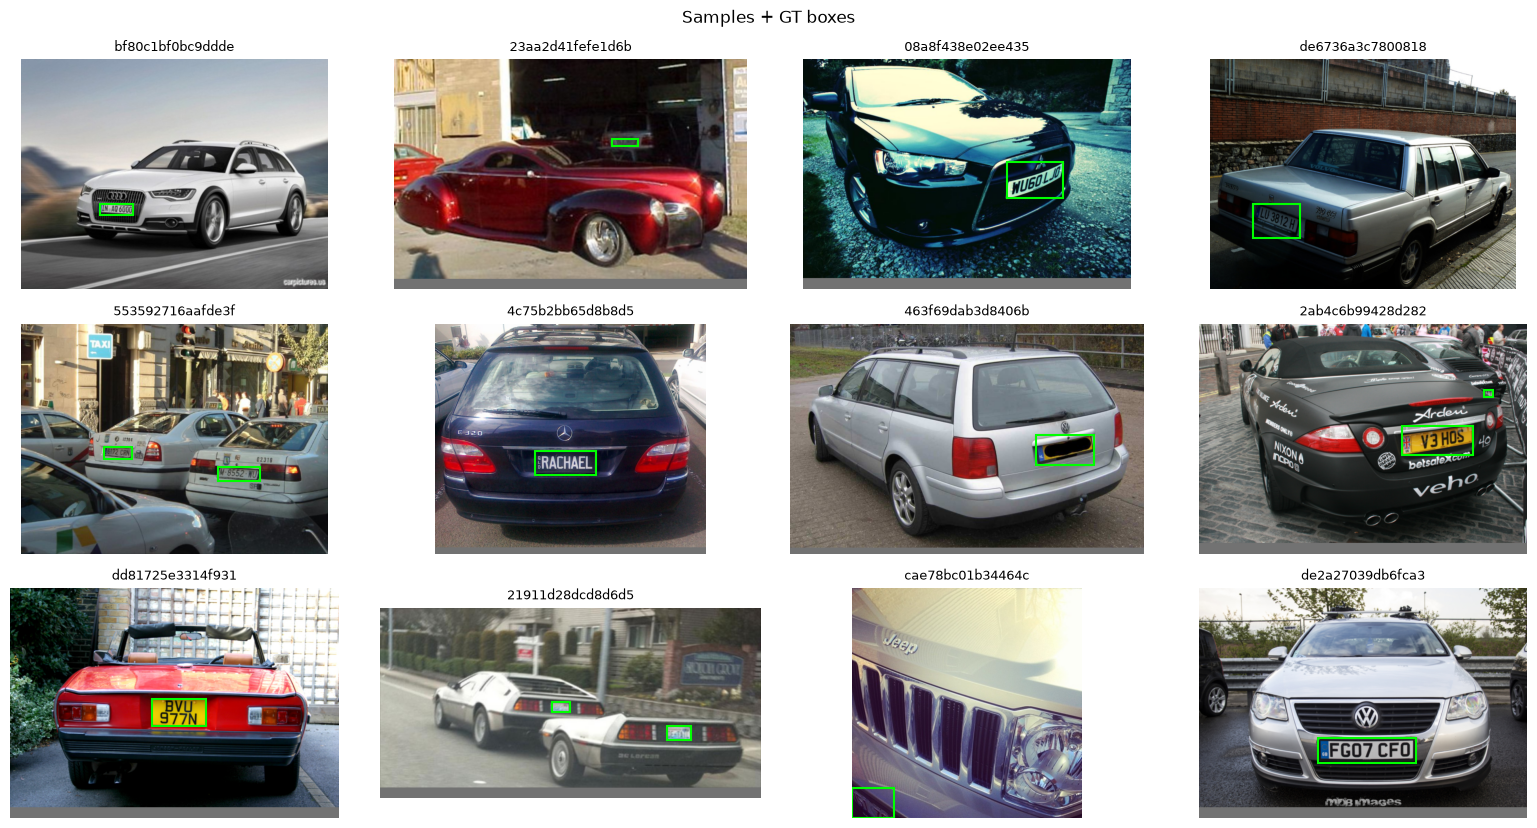

In [4]:
def show_grid(items, ncols=4, title=None):
    nrows = (len(items) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (img, boxes, label) in zip(axes.flat, items):
        ax.imshow(img.squeeze(0).permute(1, 2, 0).cpu().numpy())
        for x1, y1, x2, y2 in boxes.tolist():
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=1.5))
        ax.set_title(label, fontsize=9)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig

fig = show_grid([(*letterbox(p, b), p.name[:16]) for p, b in samples[:12]], title="Samples + GT boxes")
fig.savefig(FIG_DIR / "samples.png", dpi=110)

## 3. Clean baseline: does the detector find the plates at all?

`recall` = fraction of ground-truth plates matched by a detection (IoU >= 0.5, confidence >= 0.25).
We use Ultralytics' normal `predict()` here, including NMS, so detection is judged exactly
as a real ALPR pipeline would judge it.

In [5]:
model = YOLO(str(WEIGHTS))
net = model.model.to(device).eval()
for p in net.parameters():
    p.requires_grad_(False)  # we never update weights, only pixels

def detect(x):
    r = model.predict(source=x, conf=CONF, verbose=False)[0]
    return r.boxes.xyxy, r.boxes.conf

def plates_found(x, gt):
    pred, _ = detect(x)
    if len(pred) == 0:
        return 0
    return int((box_iou(gt, pred).max(dim=1).values >= IOU_MATCH).sum())

found = total = 0
for p, b in samples:
    x, gt = letterbox(p, b)
    found += plates_found(x, gt)
    total += len(gt)
print(f"clean recall: {found}/{total} = {found / total:.3f}")

clean recall: 187/267 = 0.700


## 4. YCbCr: separating brightness from color

YCbCr splits a pixel into **Y** (brightness) and **Cb/Cr** (blue/red color difference).
Human eyes are much more sensitive to brightness changes than color changes
(that is why JPEG stores color at lower resolution). So the idea is:
give Y a tiny budget and let the noise live mostly in Cb/Cr.

The conversion is just a fixed 3x3 matrix (ITU-R BT.601, the one JPEG uses), so it is
differentiable and gradients pass straight through it.

In [6]:
RGB2YCBCR = torch.tensor([[0.299, 0.587, 0.114],
                          [-0.168736, -0.331264, 0.5],
                          [0.5, -0.418688, -0.081312]], device=device)
YCBCR2RGB = torch.linalg.inv(RGB2YCBCR)
OFFSET = torch.tensor([0.0, 0.5, 0.5], device=device).view(1, 3, 1, 1)

def rgb_to_ycbcr(x):
    return torch.einsum("ij,bjhw->bihw", RGB2YCBCR, x) + OFFSET

def ycbcr_to_rgb(x):
    return torch.einsum("ij,bjhw->bihw", YCBCR2RGB, x - OFFSET)

err = (ycbcr_to_rgb(rgb_to_ycbcr(x0)) - x0).abs().max().item()
print(f"round-trip error: {err:.2e}")  # should be ~1e-7

round-trip error: 1.79e-07


## 5. The noise region: plate box + margin

A mask that is 1 inside each (slightly enlarged) plate box and 0 everywhere else.
Multiplying the budget by this mask means pixels outside the plate can never change.

In [7]:
def plate_mask(x, boxes):
    _, _, H, W = x.shape
    m = torch.zeros(1, 1, H, W, device=device)
    for x1, y1, x2, y2 in boxes.tolist():
        dx, dy = (x2 - x1) * MARGIN, (y2 - y1) * MARGIN
        m[..., max(0, int(y1 - dy)):min(H, int(y2 + dy) + 1),
               max(0, int(x1 - dx)):min(W, int(x2 + dx) + 1)] = 1.0
    return m

## 6. The loss: what PGD minimizes

The raw network output (before NMS) has shape `(1, 5, anchors)`:
4 box numbers + 1 plate confidence for each of ~5,000 candidate locations.

Our loss = sum of the **100 highest plate confidences**. Pushing those down
means no candidate survives the 0.25 threshold, so after NMS there is nothing left to report.
We use the top 100 rather than only the max so the gradient doesn't jump between
candidates from step to step.

In [8]:
def suppression_loss(x):
    raw = net(x)[0]          # (1, 5, A)
    scores = raw[0, 4]       # plate confidence per candidate, already sigmoid-ed
    return scores.topk(min(TOPK, scores.numel())).values.sum()

## 7. PGD: a training loop turned around

In training you fix the image and step the **weights** down the loss gradient.
In PGD you fix the weights and step the **noise** down the loss gradient. Each step:

1. build the adversarial image from the current noise `delta`
2. compute the loss and its gradient with respect to `delta`
3. step: `delta -= step_size * sign(gradient)` (sign = equal-sized step for every pixel)
4. **project**: clip `delta` back into the budget (per channel, and 0 outside the plate mask)

`delta` lives in whichever color space we are attacking in. For YCbCr we add it to
the image's YCbCr representation and convert back to RGB before the model sees it.

In [9]:
def apply(x, delta, space):
    if space == "rgb":
        return (x + delta).clamp(0, 1)
    return ycbcr_to_rgb(rgb_to_ycbcr(x) + delta).clamp(0, 1)

def pgd(x, boxes, space, eps_255):
    # The noise we'll put on each pixel
    eps = torch.tensor(eps_255, device=device).view(1, 3, 1, 1) / 255.0
    # Bounding the noise is what keeps it invisible to humans.
    bound = eps * plate_mask(x, boxes)          # per-pixel, per-channel budget
    step = 2.5 * eps / STEPS                    # common PGD heuristic: lets delta reach the edge and move along it
    delta = torch.zeros_like(x, requires_grad=True)
    for _ in range(STEPS):
        loss = suppression_loss(apply(x, delta, space))
        (grad,) = torch.autograd.grad(loss, delta)
        with torch.no_grad():
            delta -= step * grad.sign()
            delta.copy_(torch.maximum(torch.minimum(delta, bound), -bound))
    with torch.no_grad():
        return apply(x, delta, space)

def random_noise(x, boxes, eps_255):
    eps = torch.tensor(eps_255, device=device).view(1, 3, 1, 1) / 255.0
    # Sign makes a choice -1 or +1 hence the "* 2 - 1" at the end.
    sign = torch.randint(0, 2, x.shape, device=device) * 2 - 1
    # Clamp keeps the resulting value within [0,1].
    return (x + sign * eps * plate_mask(x, boxes)).clamp(0, 1)

## 8. Run all three attacks

For each image we record:
- plates found before and after the attack (two versions of "after": the float tensor,
  and the image **rounded to 8-bit** as it would be when saved as a PNG; tiny 2/255 noise could vanish in rounding)
- SSIM on the plate crop (1.0 = identical; whole-image SSIM would be inflated since most pixels are untouched)
- the largest change actually made to Y, Cb, Cr, in 1/255 units (checks the budget is respected)

In [10]:
ATTACKS = {
    "rgb_8":        lambda x, b: pgd(x, b, "rgb", [8, 8, 8]),
    "ycbcr_y2_c8":  lambda x, b: pgd(x, b, "ycbcr", [2, 8, 8]),
    "random_rgb_8": lambda x, b: random_noise(x, b, [8, 8, 8]),
}

def to_uint8(x):
    return (x * 255).round() / 255

def plate_ssim(a, b, boxes):
    # Get license plate box.
    x1, y1, x2, y2 = boxes[0].round().int().tolist()
    # Extract license plate from image, and format for scikit-image to read.
    ca = a[0, :, y1:y2, x1:x2].permute(1, 2, 0).cpu().numpy()
    cb = b[0, :, y1:y2, x1:x2].permute(1, 2, 0).cpu().numpy()
    side = min(ca.shape[:2])
    if side < 3:
        return float("nan")  # plate too thin to measure SSIM on
    win = min(7, side)
    if win % 2 == 0:
        win -= 1  # round DOWN to odd so the window still fits inside the crop
    return structural_similarity(ca, cb, channel_axis=2, data_range=1.0, win_size=win)

rows, keep = [], {}
for i, (p, b) in enumerate(samples):
    x, gt = letterbox(p, b)
    clean_found = plates_found(x, gt)
    for name, attack in ATTACKS.items():
        adv = attack(x, gt)
        adv8 = to_uint8(adv)
        dycc = (rgb_to_ycbcr(adv8) - rgb_to_ycbcr(x)).abs().amax(dim=(0, 2, 3)) * 255
        rows.append(dict(
            image=p.name, attack=name, n_plates=len(gt), clean_found=clean_found,
            adv_found=plates_found(adv, gt), adv8_found=plates_found(adv8, gt),
            plate_ssim=plate_ssim(x, adv8, gt),
            max_dY=dycc[0].item(), max_dCb=dycc[1].item(), max_dCr=dycc[2].item(),
        ))
        if i < 8:
            keep[(i, name)] = adv8
    if (i + 1) % 50 == 0:
        print(f"{i + 1}/{len(samples)} images")

df = pd.DataFrame(rows)
df.to_csv(ROOT / "spikes/02_openimages/results.csv", index=False)

50/200 images
100/200 images
150/200 images
200/200 images


## 9. Results

- `recall_*`: plates found / all plates. Clean recall is the ceiling.
- `success_rate`: of the plates the detector found on the clean image, what fraction it **lost** after the attack (8-bit).
  This is the cleanest measure of the attack itself.

In [11]:
def summarize(g):
    found_clean = g.clean_found.sum()
    return pd.Series({
        "recall_clean": found_clean / g.n_plates.sum(),
        "recall_adv_float": g.adv_found.sum() / g.n_plates.sum(),
        "recall_adv_8bit": g.adv8_found.sum() / g.n_plates.sum(),
        "success_rate": 1 - g.adv8_found.sum() / max(found_clean, 1),
        "plate_ssim_mean": g.plate_ssim.mean(),
        "plate_ssim_p10": g.plate_ssim.quantile(0.10),
        "max_dY": g.max_dY.max(), "max_dCb": g.max_dCb.max(), "max_dCr": g.max_dCr.max(),
    })

summary = df.groupby("attack", sort=False)[df.columns.drop("attack")].apply(summarize)
summary.round(3)

,recall_clean,recall_adv_float,recall_adv_8bit,success_rate,plate_ssim_mean,plate_ssim_p10,max_dY,max_dCb,max_dCr
attack,,,,,,,,,
rgb_8,0.7,0.052,0.052,0.925,0.945,0.895,8.00,8.000,8.000
ycbcr_y2_c8,0.7,0.056,0.056,0.920,0.906,0.830,5.87,10.319,9.431
random_rgb_8,0.7,0.674,0.674,0.037,0.889,0.786,8.00,8.000,8.000


## 10. Look at it yourself

Each row: clean plate crop | attacked crop (8-bit) | the noise, amplified 20x so you can see it.
Title shows whether the detector still found the plate.

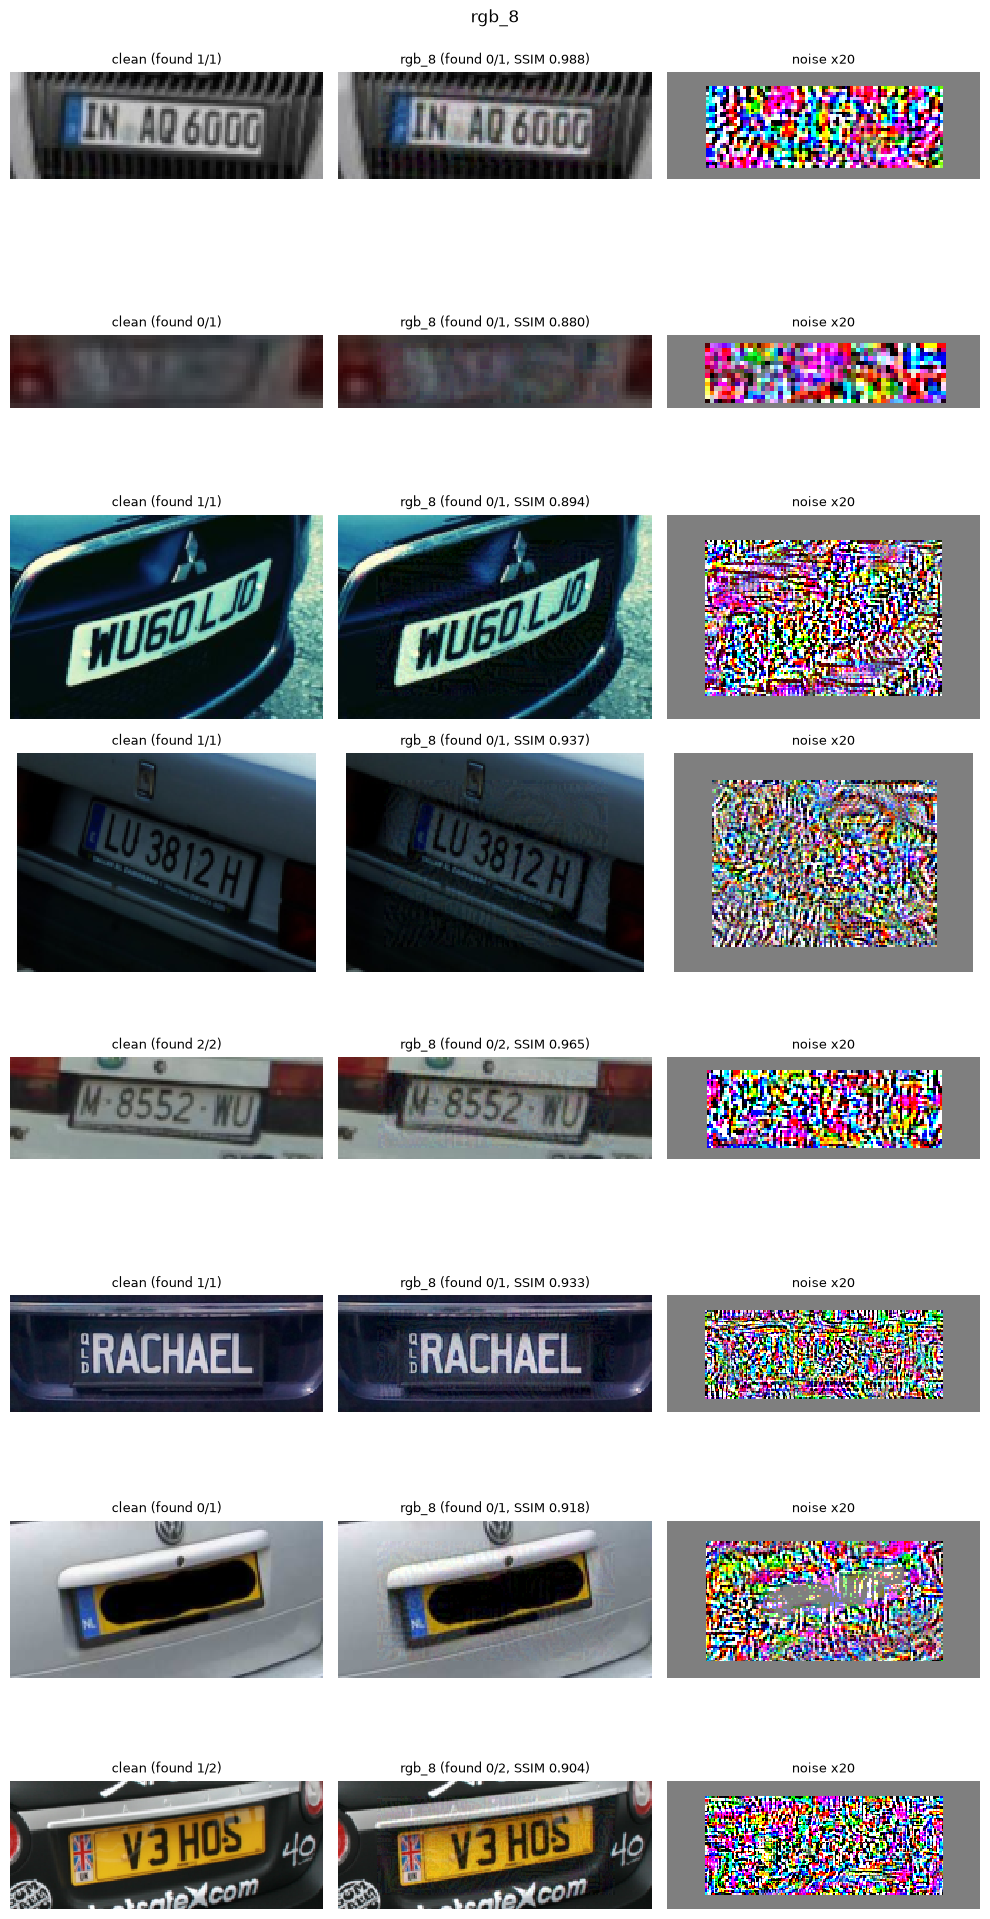

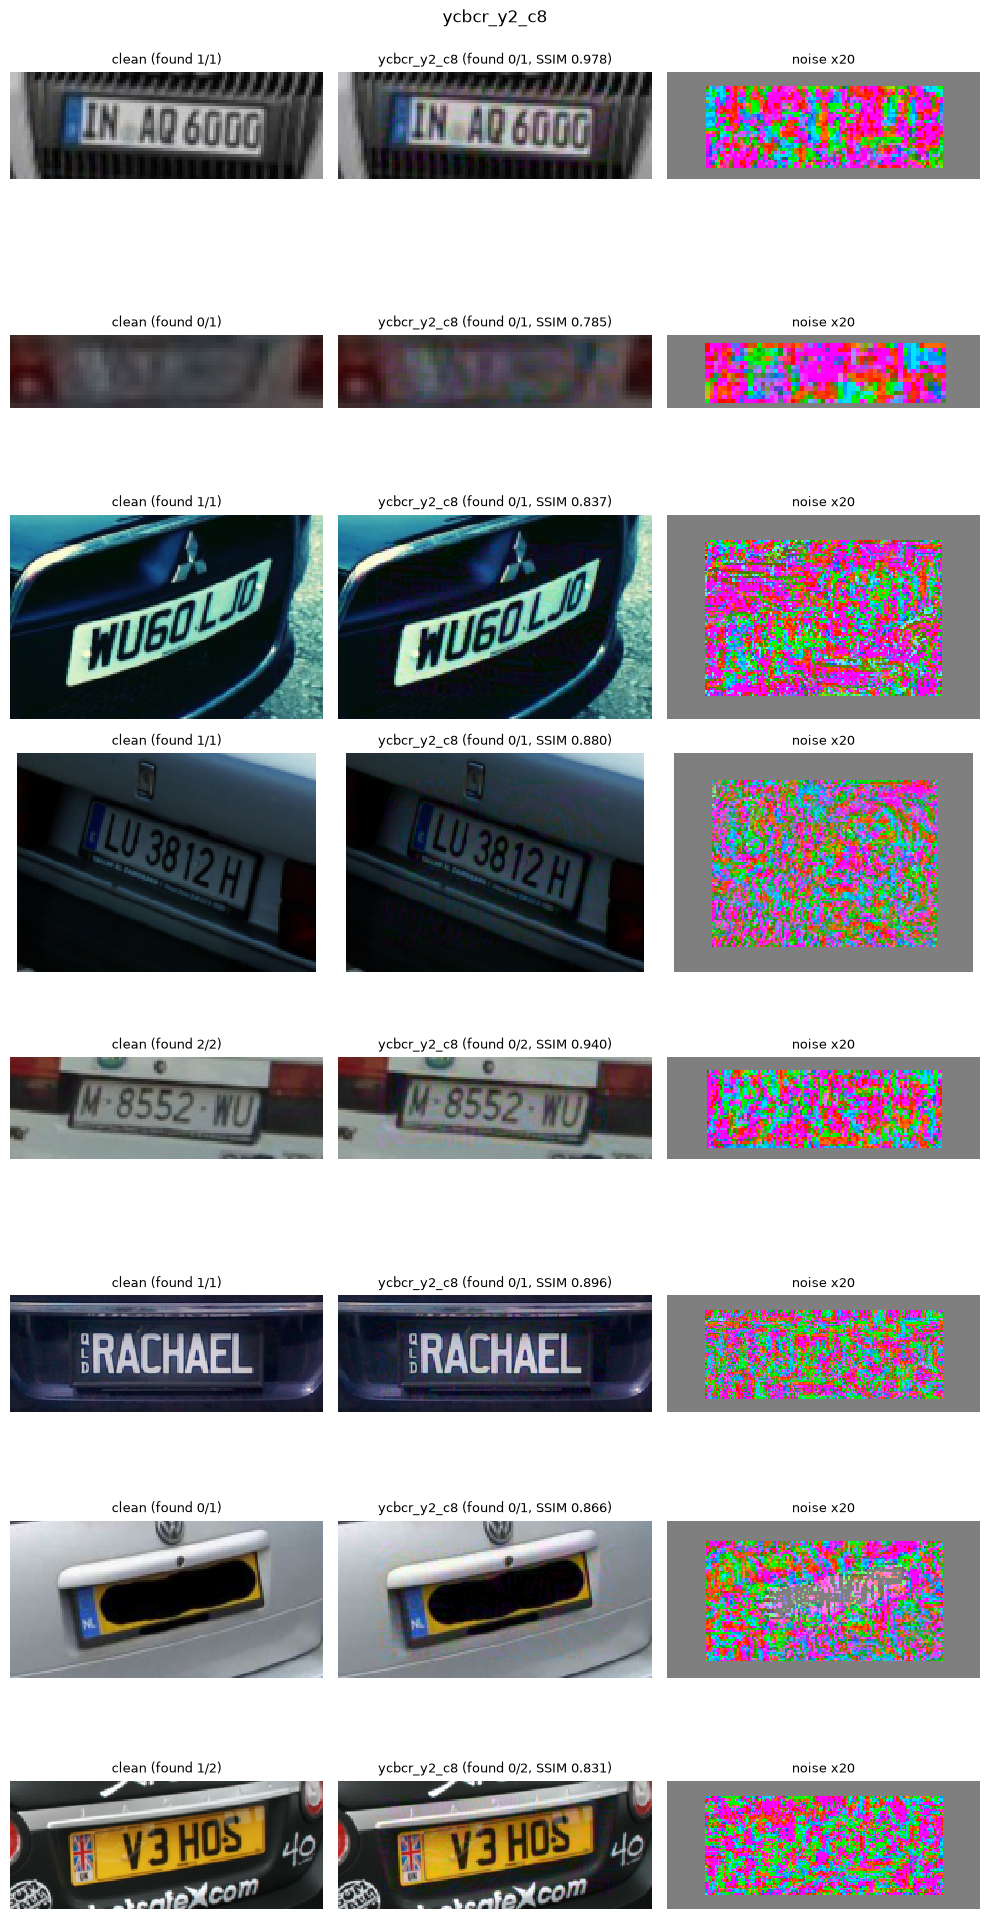

In [12]:
def crop(x, boxes, pad=0.3):
    x1, y1, x2, y2 = boxes[0].tolist()
    dx, dy = (x2 - x1) * pad, (y2 - y1) * pad
    _, _, H, W = x.shape
    return x[0, :, max(0, int(y1 - dy)):min(H, int(y2 + dy)), max(0, int(x1 - dx)):min(W, int(x2 + dx))]

def show(img, ax, title):
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1).cpu().numpy(), interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")

for name in ["rgb_8", "ycbcr_y2_c8"]:
    fig, axes = plt.subplots(8, 3, figsize=(10, 20))
    for i in range(8):
        p, b = samples[i]
        x, gt = letterbox(p, b)
        adv8 = keep[(i, name)]
        r = df[(df.image == p.name) & (df.attack == name)].iloc[0]
        show(crop(x, gt), axes[i, 0], f"clean (found {r.clean_found}/{r.n_plates})")
        show(crop(adv8, gt), axes[i, 1], f"{name} (found {r.adv8_found}/{r.n_plates}, SSIM {r.plate_ssim:.3f})")
        show(crop((adv8 - x) * 20 + 0.5, gt), axes[i, 2], "noise x20")
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"side_by_side_{name}.png", dpi=110)

## 11. What we learned

*To fill in together, comparing against Spike 01.*